# Objective 

- Convert BDD100K JSON annotations into YOLO object detection format.

# Environment and configuration

In [1]:

from pathlib import Path
from collections import Counter
import pandas as pd
import ijson
import yaml
import cv2
import random
import shutil


# 1. Project and dataset paths

PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"

TRAIN_IMAGE_DIR = DATASET_DIR / "images" / "train"
VAL_IMAGE_DIR = DATASET_DIR / "images" / "val"

ANNOTATION_DIR = DATASET_DIR / "annotations"

TRAIN_JSON = ANNOTATION_DIR / "bdd100k_labels_images_train.json"
VAL_JSON = ANNOTATION_DIR / "bdd100k_labels_images_val.json"


# 2. Final 10 detection classes


CLASS_NAMES = [
    "car",
    "traffic sign",
    "traffic light",
    "person",
    "truck",
    "bus",
    "bike",
    "rider",
    "motor",
    "train"
]

CLASS_MAPPING = {
    name: class_id
    for class_id, name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)


# 3. Output directories


PROCESSED_DIR = DATASET_DIR / "processed"

# YOLO discovers labels by replacing /images/ with /labels/
# Keep labels in a matching relative directory structure.
TRAIN_LABEL_DIR = DATASET_DIR / "labels" / "train"
VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"

MANIFEST_DIR = PROCESSED_DIR / "manifests"

TRAIN_LABEL_DIR.mkdir(parents=True, exist_ok=True)
VAL_LABEL_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)


# 4. Image extensions


IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


# 5. Verify paths

required_paths = {
    "Training images": TRAIN_IMAGE_DIR,
    "Validation images": VAL_IMAGE_DIR,
    "Training annotations": TRAIN_JSON,
    "Validation annotations": VAL_JSON
}

assert all(path.exists() for path in required_paths.values()), (
    "One or more dataset paths are incorrect."
)

print("\nCLASS CONFIGURATION\n")


for class_id, class_name in enumerate(CLASS_NAMES):
    print(f"{class_id}: {class_name}")

print("\nTotal detection classes:", NUM_CLASSES)



CLASS CONFIGURATION

0: car
1: traffic sign
2: traffic light
3: person
4: truck
5: bus
6: bike
7: rider
8: motor
9: train

Total detection classes: 10


# Build image paths and manifests

In [2]:
# 1. Index original images

def build_image_lookup(image_dir):

    lookup = {}

    for path in image_dir.rglob("*"):

        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:

            if path.name in lookup:
                raise ValueError(f"Duplicate image filename: {path.name}")

            lookup[path.name] = path.resolve()

    return lookup


train_image_lookup = build_image_lookup(TRAIN_IMAGE_DIR)
val_image_lookup = build_image_lookup(VAL_IMAGE_DIR)

print("Training images:", len(train_image_lookup))
print("Validation images:", len(val_image_lookup))

# 2. Generate manifests from annotation JSON

def generate_manifest(json_path, image_lookup, split):

    records = []

    with open(json_path, "rb") as file:

        for record in ijson.items(file, "item"):

            filename = record["name"]

            image_path = image_lookup.get(filename)

            if image_path is None:
                raise FileNotFoundError(
                    f"Annotated image not found: {filename}"
                )

            # Determine YOLO label path by mirroring image structure
            relative_path = image_path.relative_to(
                DATASET_DIR / "images"
            )

            label_path = (
                DATASET_DIR / "labels" / relative_path
            ).with_suffix(".txt")

            records.append({
                "image_name": filename,
                "image_path": str(image_path),
                "label_path": str(label_path),
                "split": split
            })

    return pd.DataFrame(records)


train_manifest = generate_manifest(
    TRAIN_JSON,
    train_image_lookup,
    "train"
)

val_manifest = generate_manifest(
    VAL_JSON,
    val_image_lookup,
    "val"
)


# 3. Save CSV manifests


train_csv = MANIFEST_DIR / "train.csv"
val_csv = MANIFEST_DIR / "val.csv"

train_manifest.to_csv(train_csv, index=False)
val_manifest.to_csv(val_csv, index=False)


# 4. Save Ultralytics image-list files


train_list = MANIFEST_DIR / "train.txt"
val_list = MANIFEST_DIR / "val.txt"

train_list.write_text(
    "\n".join(train_manifest["image_path"]) + "\n",
    encoding="utf-8"
)

val_list.write_text(
    "\n".join(val_manifest["image_path"]) + "\n",
    encoding="utf-8"
)


# 5. Display results


print("\nMANIFEST GENERATION")
print("-" * 45)

print(f"Training records   : {len(train_manifest):,}")
print(f"Validation records : {len(val_manifest):,}")

print("\nGenerated files:")
print(train_csv)
print(val_csv)
print(train_list)
print(val_list)

display(train_manifest.head())


Training images: 69863
Validation images: 10000

MANIFEST GENERATION
---------------------------------------------
Training records   : 69,863
Validation records : 10,000

Generated files:
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\processed\manifests\train.csv
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\processed\manifests\val.csv
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\processed\manifests\train.txt
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\processed\manifests\val.txt


,image_name,image_path,label_path,split
0,0000f77c-6257be58.jpg,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,train
1,0000f77c-62c2a288.jpg,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,train
2,0000f77c-cb820c98.jpg,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,train
3,0001542f-5ce3cf52.jpg,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,train
4,0001542f-7c670be8.jpg,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...,train


# Bounding-box coordinate conversion

BDD100K provides pixel coordinates:
\\[
(x_1,y_1,x_2,y_2)
\\]

YOLO requires normalized coordinates:
\\[
(x_c,y_c,w,h)
\\]

In [3]:

def convert_bbox_to_yolo(box, image_width, image_height):

    # Convert JSON string coordinates into floats
    x1 = float(box["x1"])
    y1 = float(box["y1"])
    x2 = float(box["x2"])
    y2 = float(box["y2"])

    # Clip coordinates to image boundaries
    x1 = max(0.0, min(x1, image_width))
    y1 = max(0.0, min(y1, image_height))
    x2 = max(0.0, min(x2, image_width))
    y2 = max(0.0, min(y2, image_height))

    # Calculate bounding-box dimensions
    box_width = x2 - x1
    box_height = y2 - y1

    # Reject zero-area or invalid boxes
    if box_width <= 0 or box_height <= 0:
        return None

    # Convert to normalized YOLO coordinates
    x_center = ((x1 + x2) / 2) / image_width
    y_center = ((y1 + y2) / 2) / image_height

    normalized_width = box_width / image_width
    normalized_height = box_height / image_height

    return (
        x_center,
        y_center,
        normalized_width,
        normalized_height
    )


In [4]:

test_box = {
    "x1": "100",
    "y1": "100",
    "x2": "300",
    "y2": "300"
}

result = convert_bbox_to_yolo(
    test_box,
    image_width=1280,
    image_height=720
)

print("YOLO coordinates:", result)



YOLO coordinates: (0.15625, 0.2777777777777778, 0.15625, 0.2777777777777778)


# Generate YOLO annotation files

In [5]:

from tqdm.auto import tqdm
from collections import Counter
from PIL import Image
import ijson

def convert_dataset(json_path, image_lookup, split):

    stats = Counter()
    class_counts = Counter()

    total_records = (
        len(train_manifest) if split == "train"
        else len(val_manifest)
    )

    with open(json_path, "rb") as file:

        records = ijson.items(file, "item")

        progress = tqdm(
            records,
            total=total_records,
            desc=f"Converting {split}",
            unit="image"
        )

        for record in progress:

            filename = record["name"]
            image_path = image_lookup.get(filename)

            if image_path is None:
                raise FileNotFoundError(
                    f"Annotated image not found: {filename}"
                )

            relative_path = image_path.relative_to(
                DATASET_DIR / "images"
            )

            label_path = (
                DATASET_DIR / "labels" / relative_path
            ).with_suffix(".txt")

            label_path.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            # PIL handles Windows Unicode paths reliably
            try:
                with Image.open(image_path) as image:
                    image_width, image_height = image.size

            except Exception as error:
                raise ValueError(
                    f"Unable to read image: {image_path}"
                ) from error

            yolo_labels = []

            for obj in record.get("labels", []):

                category = obj.get("category")

                if category not in CLASS_MAPPING:
                    stats["ignored_category"] += 1
                    continue

                box = obj.get("box2d")

                if not box:
                    stats["missing_box"] += 1
                    continue

                coordinates = convert_bbox_to_yolo(
                    box,
                    image_width,
                    image_height
                )

                if coordinates is None:
                    stats["invalid_box"] += 1
                    continue

                class_id = CLASS_MAPPING[category]

                x_center, y_center, width, height = coordinates

                yolo_line = (
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}"
                )

                yolo_labels.append(yolo_line)

                class_counts[category] += 1
                stats["valid_boxes"] += 1

            label_path.write_text(
                "\n".join(yolo_labels),
                encoding="utf-8"
            )

            stats["images_processed"] += 1

            if not yolo_labels:
                stats["empty_label_files"] += 1

            progress.set_postfix(
                boxes=stats["valid_boxes"],
                invalid=stats["invalid_box"]
            )

    return stats, class_counts


In [6]:

print("STARTING TRAINING CONVERSION")

train_stats, train_class_counts = convert_dataset(
    TRAIN_JSON,
    train_image_lookup,
    "train"
)

print("\nSTARTING VALIDATION CONVERSION")

val_stats, val_class_counts = convert_dataset(
    VAL_JSON,
    val_image_lookup,
    "val"
)

print("\nBOTH DATASETS CONVERTED SUCCESSFULLY!")


STARTING TRAINING CONVERSION


Converting train:   0%|          | 0/69863 [00:00<?, ?image/s]


STARTING VALIDATION CONVERSION


Converting val:   0%|          | 0/10000 [00:00<?, ?image/s]


BOTH DATASETS CONVERTED SUCCESSFULLY!


# Validate generated YOLO labels

In [7]:
from pathlib import Path
import math

def validate_yolo_labels(manifest, split):

    total_images = len(manifest)
    missing_files = 0
    empty_files = 0
    invalid_lines = 0
    valid_lines = 0
    invalid_class_ids = 0
    invalid_coordinates = 0

    for _, row in manifest.iterrows():

        label_path = Path(row["label_path"])

        if not label_path.exists():
            missing_files += 1
            continue

        with open(label_path, "r") as file:
            lines = file.readlines()

        if not lines:
            empty_files += 1
            continue

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                invalid_lines += 1
                continue

            try:
                class_id = int(values[0])
                coordinates = [float(x) for x in values[1:]]

            except ValueError:
                invalid_lines += 1
                continue

            if not all(math.isfinite(x) for x in coordinates):
                invalid_lines += 1
                continue

            if class_id < 0 or class_id >= NUM_CLASSES:
                invalid_class_ids += 1
                continue

            x_center, y_center, width, height = coordinates

            if not (
                0 < x_center < 1
                and 0 < y_center < 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                invalid_coordinates += 1
                continue

            valid_lines += 1

    results = {
        "split": split,
        "total_images": total_images,
        "missing_label_files": missing_files,
        "empty_label_files": empty_files,
        "valid_annotations": valid_lines,
        "invalid_lines": invalid_lines,
        "invalid_class_ids": invalid_class_ids,
        "invalid_coordinates": invalid_coordinates
    }

    return results

In [9]:
import json

train_validation = validate_yolo_labels(
    train_manifest,
    "train"
)

val_validation = validate_yolo_labels(
    val_manifest,
    "val"
)

print("TRAIN VALIDATION")
print(json.dumps(train_validation, indent=4, default=str))

print("\nVALIDATION DATASET")
print(json.dumps(val_validation, indent=4, default=str))

TRAIN VALIDATION
{
    "split": "train",
    "total_images": 69863,
    "missing_label_files": 0,
    "empty_label_files": 0,
    "valid_annotations": 1286871,
    "invalid_lines": 0,
    "invalid_class_ids": 0,
    "invalid_coordinates": 0
}

VALIDATION DATASET
{
    "split": "val",
    "total_images": 10000,
    "missing_label_files": 0,
    "empty_label_files": 0,
    "valid_annotations": 185526,
    "invalid_lines": 0,
    "invalid_class_ids": 0,
    "invalid_coordinates": 0
}


# Visualize converted YOLO annotations

In [10]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import random

def visualize_yolo_sample(manifest, num_samples=4):

    samples = manifest.sample(
        n=min(num_samples, len(manifest)),
        random_state=42
    )

    fig, axes = plt.subplots(
        len(samples), 1,
        figsize=(14, 6 * len(samples))
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, samples.iterrows()):

        image_path = Path(row["image_path"])
        label_path = Path(row["label_path"])

        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        draw = ImageDraw.Draw(image)

        with open(label_path, "r") as file:
            lines = file.readlines()

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            x_center, y_center, width, height = map(
                float, values[1:]
            )

            x1 = int((x_center - width / 2) * image_width)
            y1 = int((y_center - height / 2) * image_height)
            x2 = int((x_center + width / 2) * image_width)
            y2 = int((y_center + height / 2) * image_height)

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="lime",
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                CLASS_NAMES[class_id],
                fill="red"
            )

        ax.imshow(image)
        ax.set_title(image_path.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

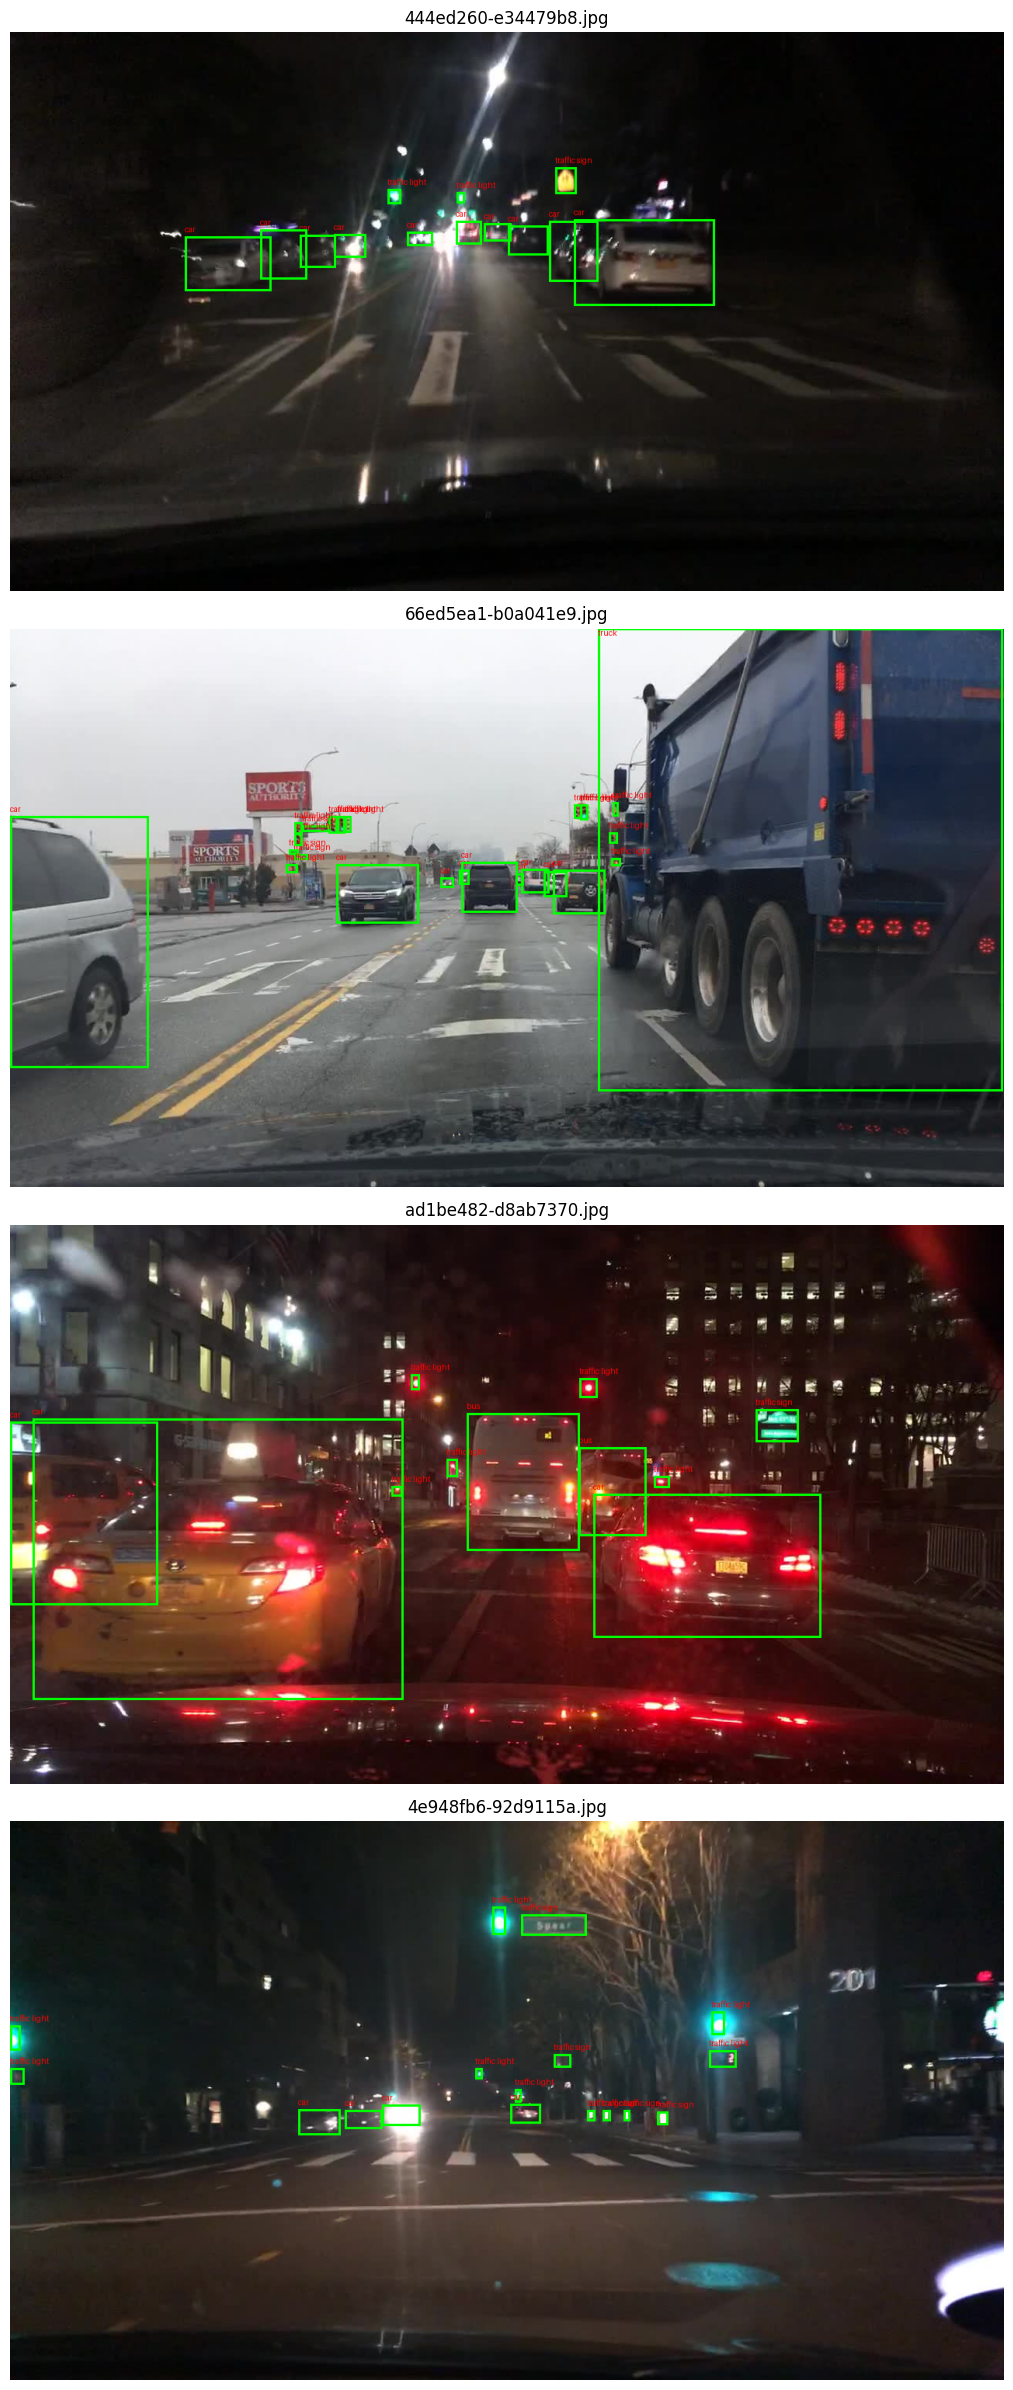

In [11]:
visualize_yolo_sample(train_manifest, num_samples=4)

# Generate YOLO data.yaml

In [12]:
import yaml

DATA_YAML = PROCESSED_DIR / "data.yaml"

dataset_config = {
    "path": DATASET_DIR.resolve().as_posix(),

    "train": "processed/manifests/train.txt",

    "val": "processed/manifests/val.txt",

    "names": CLASS_NAMES
}

with open(DATA_YAML, "w", encoding="utf-8") as file:

    yaml.safe_dump(
        dataset_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )

print("YOLO DATASET CONFIGURATION CREATED!")
print(DATA_YAML)

with open(DATA_YAML, "r", encoding="utf-8") as file:
    print(file.read())

YOLO DATASET CONFIGURATION CREATED!
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\processed\data.yaml
path: Y:/Python/AI ML/Month 2/week 8-NLP/50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION/dataset
train: processed/manifests/train.txt
val: processed/manifests/val.txt
names:
- car
- traffic sign
- traffic light
- person
- truck
- bus
- bike
- rider
- motor
- train

